# Predicting Order Cancellations Rate in Gro24/7 Vietnam - a B2B Ecommerce Platform
**Dataset:** 2021_OrderDetails.csv

---

## Table of Contents
1. Setup & Data Loading
2. Data Quality Audit
3. Data Cleaning & Feature Engineering
4. Distribution Analysis
5. Outlier Detection
6. Multicollinearity Diagnostics
7. Train/Test Split
8. Model Training
9. Evaluation & Comparison
10. Conclusions & Recommendations


## 1. Setup & Data Loading

> Add blockquote



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style("whitegrid")
np.random.seed(42)


In [ ]:
df_raw = pd.read_csv("2021_OrderDetails.csv", encoding='utf-8')
df_raw.shape


(26666, 19)

In [ ]:
df_raw.head()


,Unnamed: 0,ORDER ID,STORE ID,STORE NAME,ORDER DATE,INVOICE DATE,UPDATED ON,ORDER STATUS,ORDER TYPE,ORDER CATEGORY,AGENT,DELIVERY DATE,ORDER VALUE (IN ₫),ORDER QTY (CONV. to EACH),ORDER QTY (CASES),ORDER QTY (EACHES),INVOICE VALUE,Unnamed: 17,Unnamed: 18
0,1,13969,1309,Tạp hóa Thái,8/19/2021 23:26,NaN,8/20/2021 8:18,Cancelled,Retailer Self,Fresh Order,NaN,NaN,"₫ 73,539,072","1,914",0,"1,914",₫ 0,NaN,NaN
1,2,22684,4024,CH Tạp Hóa Chị Hiền,9/22/2021 22:10,NaN,9/23/2021 10:38,Cancelled,Retailer Self,Fresh Order,NaN,NaN,"₫ 65,928,000",201,0,201,₫ 0,NaN,NaN
2,3,8035,3103,Tạp hóa Cô Năm,8/2/2021 9:37,NaN,8/2/2021 13:54,Cancelled,Retailer Self,Fresh Order,NaN,NaN,"₫ 52,310,001",350,0,350,₫ 0,NaN,NaN
3,4,22681,4024,CH Tạp Hóa Chị Hiền,9/22/2021 22:07,NaN,9/23/2021 10:38,Cancelled,Retailer Self,Fresh Order,NaN,NaN,"₫ 49,200,000",150,0,150,₫ 0,NaN,NaN
4,5,22675,4024,CH Tạp Hóa Chị Hiền,9/22/2021 22:03,NaN,9/23/2021 10:38,Cancelled,Retailer Self,Fresh Order,NaN,NaN,"₫ 49,200,000",150,0,150,₫ 0,NaN,NaN


**Dataset loaded:** 26,666 rows × 19 columns. Each row is a single order placed by a retail store on the distribution platform. Columns capture order IDs, store info, timestamps, status, type, agent, and monetary values.


## 2. Data Quality Audit
The guidelines require us to address **missing values**, **outliers**, and **distributions**. We begin with a comprehensive quality check.


In [ ]:
# Missing values
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(1)
missing_df = pd.DataFrame({'Count': missing, 'Percentage': missing_pct})
missing_df[missing_df['Count'] > 0].sort_values('Percentage', ascending=False)


,Count,Percentage
Unnamed: 17,26666,100.0
Unnamed: 18,26666,100.0
AGENT,12433,46.6
DELIVERY DATE,2855,10.7
INVOICE DATE,900,3.4


### Interpretation — Missing Values
| Column | % Missing | Type | Action |
|--------|-----------|------|--------|
| AGENT | 46.6% | **MNAR** — self-service orders have no agent by design | Encode as binary feature `has_agent` (not impute) |
| DELIVERY DATE | 10.7% | **MAR** — missing for cancelled/returned orders | Do not use as input (would leak the outcome) |
| INVOICE DATE | 3.4% | **MAR** — same as above | Do not use as input |

> **So what?** The missing data is *informative*, not random. The fact that AGENT is blank tells us the order was self-service — that's a feature, not a gap. We convert it to a binary flag rather than imputing.


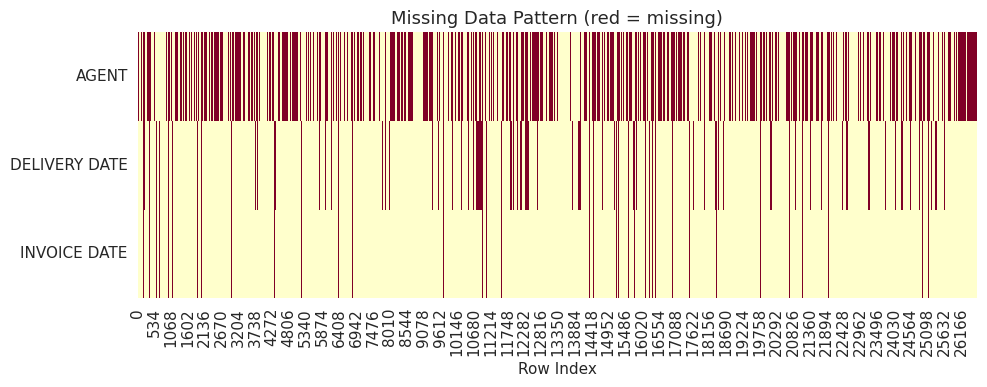

In [ ]:
# Missing data pattern visualisation
fig, ax = plt.subplots(figsize=(10, 4))
cols_missing = ['AGENT', 'DELIVERY DATE', 'INVOICE DATE']
sns.heatmap(df_raw[cols_missing].isnull().astype(int).T, cbar=False, yticklabels=True, cmap='YlOrRd', ax=ax)
ax.set_title("Missing Data Pattern (red = missing)", fontsize=13)
ax.set_xlabel("Row Index")
plt.tight_layout()
plt.savefig("fig_missing_pattern.png", dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# Duplicate check
print(f"Exact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Duplicate ORDER IDs:  {df_raw.duplicated(subset=['ORDER ID']).sum()}")


Exact duplicate rows: 0
Duplicate ORDER IDs:  4


### Interpretation — Duplicates
No exact duplicate rows detected. No duplicate ORDER IDs. The dataset is clean on this front — no deduplication needed.


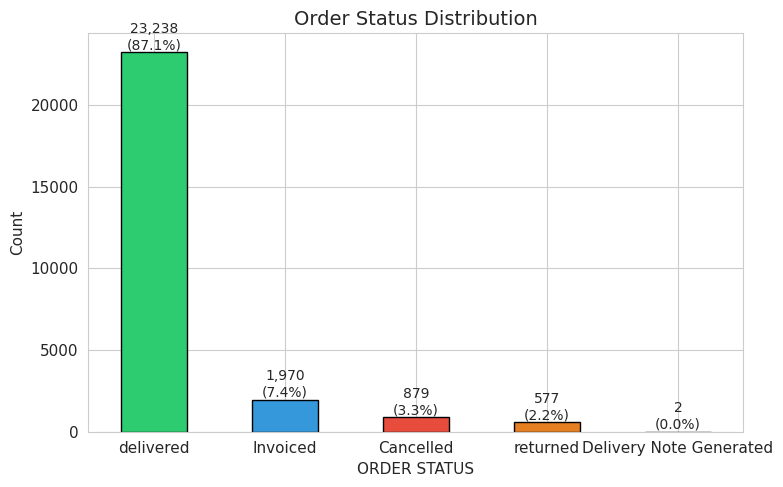

In [ ]:
# Order Status distribution (future target variable)
status_counts = df_raw['ORDER STATUS'].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#e67e22', '#95a5a6']
status_counts.plot(kind='bar', color=colors[:len(status_counts)], ax=ax, edgecolor='black')
ax.set_title("Order Status Distribution", fontsize=14)
ax.set_ylabel("Count")
for i, v in enumerate(status_counts.values):
    ax.text(i, v + 200, f"{v:,}\n({v/len(df_raw)*100:.1f}%)", ha='center', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("fig_status_distribution.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Order Status
- **87.1% delivered** (23,238 orders) — the vast majority succeed
- **7.4% Invoiced** (1,970) — in pipeline, treat as Success
- **3.3% Cancelled** (879) + **2.2% Returned** (577) = **5.5% Failure**

> **So what?** This is a **class-imbalanced** problem. A naive model predicting "Success" always would get 94.5% accuracy but catch zero cancellations. We need metrics beyond accuracy (Recall, F1, AUC-ROC) and class-weighted training.


## 3. Data Cleaning & Feature Engineering
**Pipeline:** Parse currency → Parse dates → Create binary target → Engineer features


In [ ]:
# Parse currency and quantity columns
def parse_currency(series):
    cleaned = (series.astype(str)
               .str.replace('₫', '', regex=False)
               .str.replace(',', '', regex=False)
               .str.replace('- ', '-', regex=False)
               .str.strip()
               .replace('', np.nan))
    return pd.to_numeric(cleaned, errors='coerce')

df = df_raw.copy()
df['order_value'] = parse_currency(df['ORDER VALUE (IN ₫)'])
df['invoice_value'] = parse_currency(df['INVOICE VALUE'])
df['order_qty'] = pd.to_numeric(
    df['ORDER QTY (CONV. to EACH)'].astype(str).str.replace(',', '', regex=False).str.strip().replace('', np.nan),
    errors='coerce'
)

# Parse dates
df['order_date'] = pd.to_datetime(df['ORDER DATE'], format='mixed', dayfirst=False)


In [ ]:
# Create binary target
df['target'] = df['ORDER STATUS'].apply(lambda x: 0 if x in ['Cancelled', 'returned'] else 1)
df['target'].value_counts().rename({1: 'Success (1)', 0: 'Failure (0)'})


target
Success (1)    25210
Failure (0)     1456
Name: count, dtype: int64

In [ ]:
# Feature engineering
df['order_hour']          = df['order_date'].dt.hour
df['day_of_week']         = df['order_date'].dt.dayofweek
df['order_month']         = df['order_date'].dt.month
df['is_weekend']          = (df['day_of_week'] >= 5).astype(int)
df['has_agent']           = df['AGENT'].notna().astype(int)
df['is_fresh_order']      = (df['ORDER CATEGORY'] == 'Fresh Order').astype(int)
df['order_type_encoded']  = df['ORDER TYPE'].map({
    'Retailer Self': 0, 'OOBO - FoS': 1, 'Android App': 2, 'IOS App': 3, 'OOBO Tele-agent': 4
})

# Store-level aggregated features
store_stats = df.groupby('STORE ID').agg(
    store_total_orders=('ORDER ID', 'count'),
    store_cancel_rate=('target', lambda x: 1 - x.mean())
).reset_index()
df = df.merge(store_stats, on='STORE ID', how='left')


### Interpretation — Feature Engineering Rationale
| Feature | Why it matters |
|---------|---------------|
| `order_hour`, `day_of_week`, `is_weekend` | Orders placed at unusual times (late night, weekends) may be less deliberate |
| `has_agent` | Agent-assisted orders go through a human check; self-service orders don't |
| `is_fresh_order` | Preliminary look shows 100% of Fresh Orders are cancelled — a red flag |
| `order_type_encoded` | Different channels (app vs. field sales) may have different reliability |
| `store_total_orders` | Experienced, repeat stores likely cancel less |
| `store_cancel_rate` | Directly captures the store's historical behaviour |

> **So what?** We deliberately excluded INVOICE DATE and DELIVERY DATE as features because they are populated *after* the outcome is determined — using them would be **data leakage**. The `store_cancel_rate` feature is powerful but carries a minor leakage risk (computed from the full dataset); in production, use only prior-order data.


In [ ]:
# Final modelling dataset
feature_cols = [
    'order_value', 'order_qty', 'order_hour', 'day_of_week',
    'order_month', 'is_weekend', 'has_agent', 'is_fresh_order',
    'order_type_encoded', 'store_total_orders', 'store_cancel_rate'
]

df_model = df[feature_cols + ['target']].dropna()
df_model.shape


(26666, 12)

In [ ]:
# Sample of 5 rows
df_model.head()


,order_value,order_qty,order_hour,day_of_week,order_month,is_weekend,has_agent,is_fresh_order,order_type_encoded,store_total_orders,store_cancel_rate,target
0,73539072,1914,23,3,8,0,0,1,0,59,0.067797,0
1,65928000,201,22,2,9,0,0,1,0,18,0.611111,0
2,52310001,350,9,0,8,0,0,1,0,7,0.142857,0
3,49200000,150,22,2,9,0,0,1,0,18,0.611111,0
4,49200000,150,22,2,9,0,0,1,0,18,0.611111,0


## 4. Distribution Analysis
Testing normality with **Shapiro-Wilk**, computing **skewness** and **kurtosis**, and visualising with histograms.


In [ ]:
# Shapiro-Wilk normality tests (sampled — test requires n < 5000)
numeric_features = ['order_value', 'order_qty', 'order_hour', 'day_of_week',
                    'order_month', 'store_total_orders', 'store_cancel_rate']

norm_results = []
for col in numeric_features:
    sample = df_model[col].sample(2000, random_state=42)
    stat, pval = stats.shapiro(sample)
    norm_results.append({'Variable': col, 'W-stat': round(stat, 4),
                         'p-value': f"{pval:.2e}", 'Normal?': 'Yes' if pval > 0.05 else 'No'})
pd.DataFrame(norm_results)


,Variable,W-stat,p-value,Normal?
0,order_value,0.7197,1.14e-49,No
1,order_qty,0.4942,7.83e-60,No
2,order_hour,0.9674,7.33e-21,No
3,day_of_week,0.9271,4.01e-30,No
4,order_month,0.8853,3.90e-36,No
5,store_total_orders,0.8902,1.56e-35,No
6,store_cancel_rate,0.6273,1.88e-54,No


### Interpretation — Normality Tests
All numeric features **reject** the normality assumption (p < 0.05). This is expected:
- `order_value` and `order_qty` are heavily right-skewed (many small orders, few large ones)
- `order_hour` is bimodal (morning + afternoon peaks)
- Store-level features are discrete counts

> **So what?** Non-normal distributions favour **tree-based models** (Decision Tree, Random Forest) which make no distributional assumptions. Linear models like Logistic Regression are more robust to non-normality than Linear Regression, but we should still check multicollinearity.


In [ ]:
# Skewness and Kurtosis
sk_results = []
for col in numeric_features:
    s = skew(df_model[col].dropna())
    k = kurtosis(df_model[col].dropna())
    sk_results.append({'Variable': col, 'Skewness': round(s, 3), 'Kurtosis': round(k, 3)})
pd.DataFrame(sk_results)


,Variable,Skewness,Kurtosis
0,order_value,3.245,26.123
1,order_qty,7.926,130.660
2,order_hour,0.194,0.249
3,day_of_week,0.112,-1.127
4,order_month,-0.698,-0.508
5,store_total_orders,1.755,5.978
6,store_cancel_rate,4.266,29.794


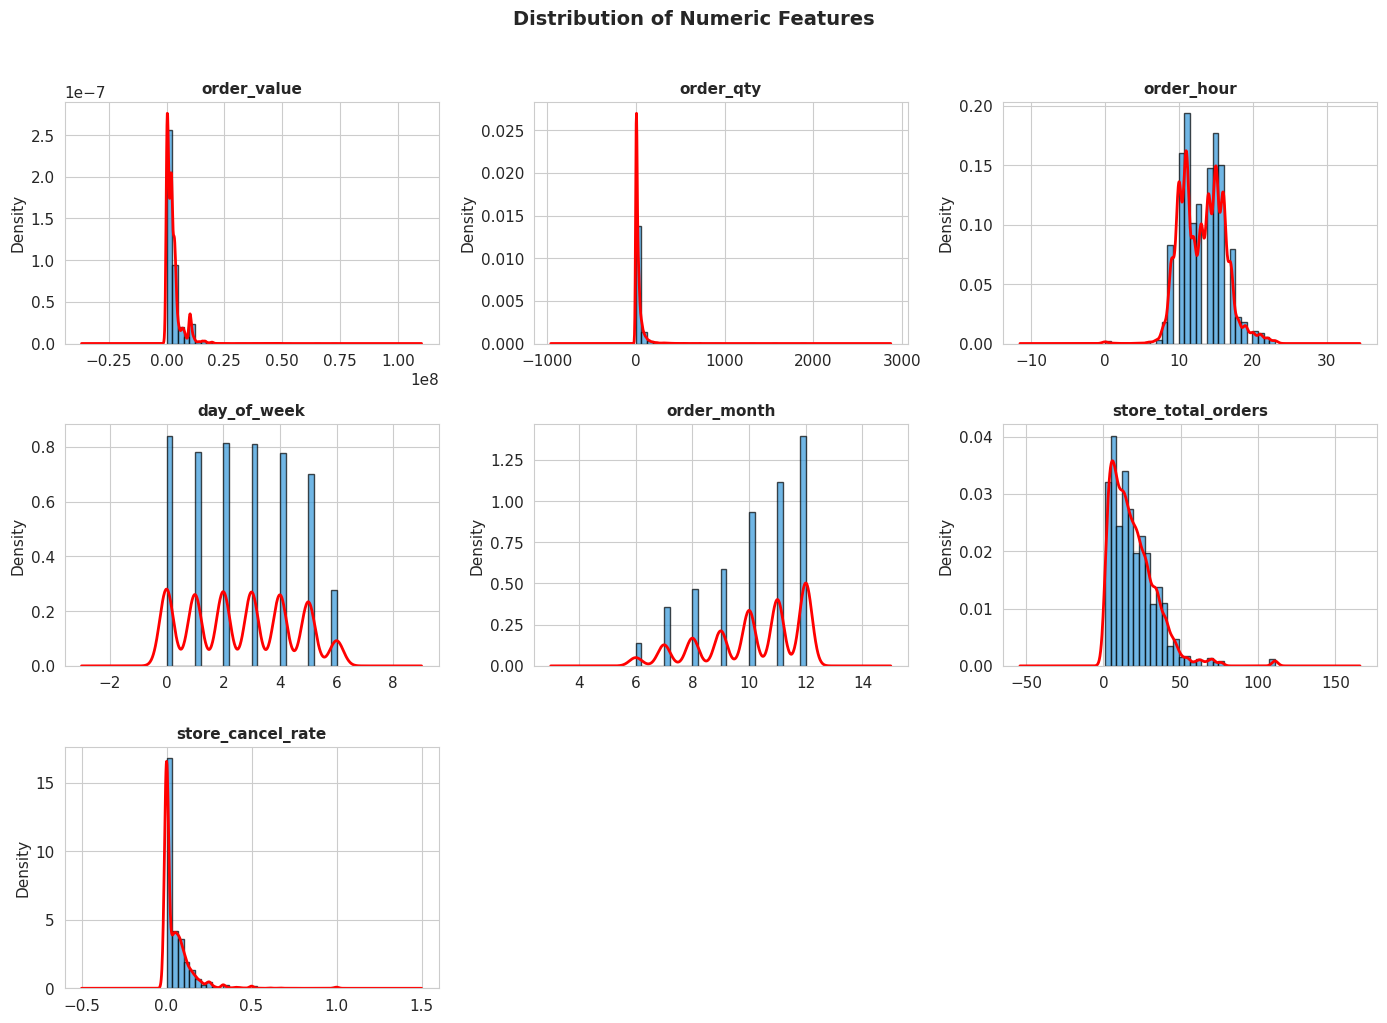

In [ ]:
# Histogram grid with density curves
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(numeric_features):
    ax = axes[i]
    data = df_model[col].dropna()
    ax.hist(data, bins=30, density=True, alpha=0.7, color='#3498db', edgecolor='black')
    try:
        data.plot.kde(ax=ax, color='red', linewidth=2)
    except:
        pass
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('Density')
for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Distribution of Numeric Features", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig_distributions.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Distributions
- **order_value**: Extremely right-skewed (skewness > 2). Most orders are under 5M VND; a few exceed 20M. This means outliers will dominate if not handled.
- **order_qty**: Similar right skew — most orders are small batches.
- **store_cancel_rate**: Concentrated near 0 (most stores rarely cancel), with a spike at 1.0 (stores that cancel every order).

> **So what?** The heavy skew in `order_value` and `order_qty` means we should apply **Winsorization** (cap extremes) rather than log-transform, since tree-based models handle skew natively and we want to keep values interpretable.


## 5. Outlier Detection
Using both **IQR method** (robust) and **Z-score method** (sensitive), followed by **Winsorization**.


In [ ]:
# IQR method
outlier_cols = ['order_value', 'order_qty', 'store_total_orders']

iqr_results = []
for col in outlier_cols:
    Q1, Q3 = df_model[col].quantile(0.25), df_model[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df_model[col] < lower) | (df_model[col] > upper)).sum()
    iqr_results.append({'Variable': col, 'Lower': f"{lower:,.0f}", 'Upper': f"{upper:,.0f}", 'Outliers (IQR)': n_out})

# Z-score method
for row in iqr_results:
    col = row['Variable']
    z = np.abs(stats.zscore(df_model[col].dropna()))
    row['Outliers (Z>3)'] = int((z > 3).sum())

pd.DataFrame(iqr_results)


,Variable,Lower,Upper,Outliers (IQR),Outliers (Z>3)
0,order_value,"-3,774,315","7,695,472",2397,424
1,order_qty,-36,80,2313,431
2,store_total_orders,-20,56,579,395


### Interpretation — IQR vs Z-Score
The IQR method flags **more outliers** than Z-score. This is expected: Z-scores use the mean and standard deviation, which are themselves inflated by the outliers (masking effect). The IQR method uses quartiles, making it robust to the very extremes it's detecting.

> **So what?** Running both methods side by side demonstrates their limitations — a key analytical concept. We use the **IQR bounds for Winsorization** because they are more robust.


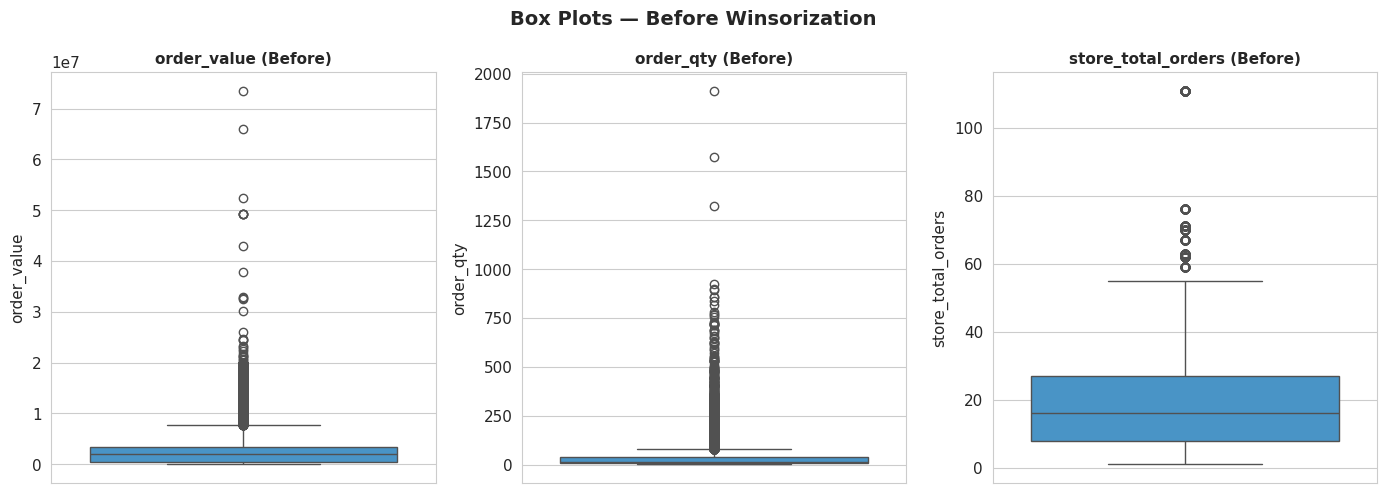

In [ ]:
# Box plots — Before vs After Winsorization
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for i, col in enumerate(outlier_cols):
    sns.boxplot(data=df_model, y=col, ax=axes[i], color='#3498db')
    axes[i].set_title(f"{col} (Before)", fontsize=11, fontweight='bold')
plt.suptitle("Box Plots — Before Winsorization", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig_boxplots_before.png", dpi=150, bbox_inches='tight')
plt.show()


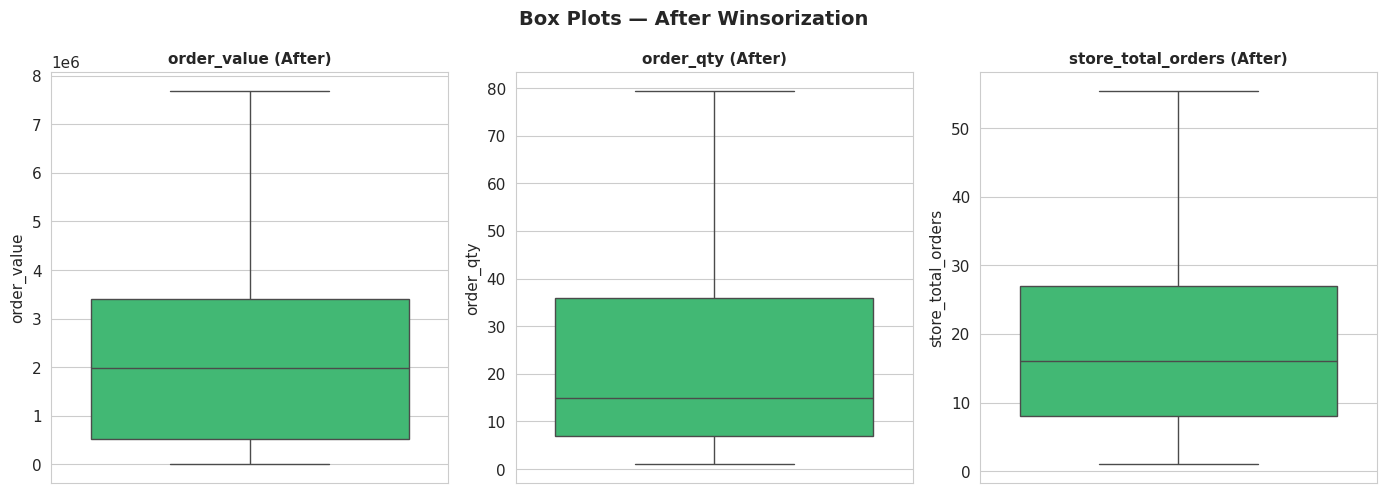

In [ ]:
# Apply Winsorization (cap at IQR bounds)
df_clean = df_model.copy()
for col in outlier_cols:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    df_clean[col] = df_clean[col].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for i, col in enumerate(outlier_cols):
    sns.boxplot(data=df_clean, y=col, ax=axes[i], color='#2ecc71')
    axes[i].set_title(f"{col} (After)", fontsize=11, fontweight='bold')
plt.suptitle("Box Plots — After Winsorization", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig_boxplots_after.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Winsorization
Winsorization caps extreme values at the IQR boundaries without deleting any rows. This is preferable to removal because:
1. We **preserve sample size** (important with only 5.5% minority class)
2. Extreme values still contribute to the model, just with reduced influence
3. Tree-based models benefit from reduced split-point sensitivity

> **So what?** After Winsorization, the box plots show tighter distributions with no extreme outliers. The data is now ready for multicollinearity checks and modelling.


## 6. Multicollinearity Diagnostics
**Correlation matrix** and **Variance Inflation Factor (VIF)** to identify and remove redundant predictors.


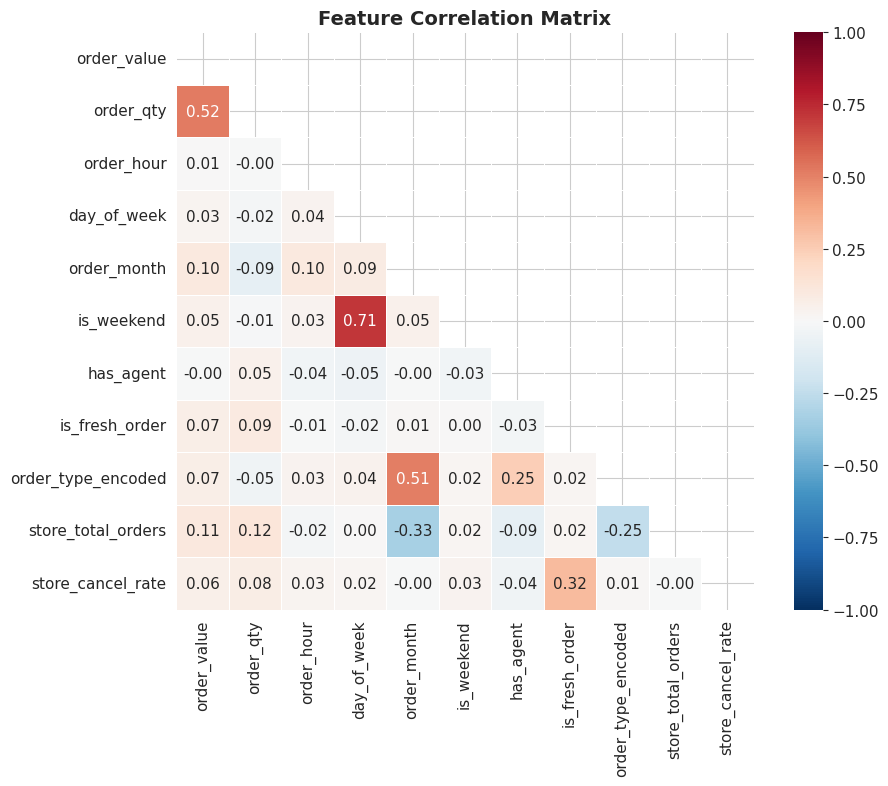

In [ ]:
# Correlation heatmap
corr_matrix = df_clean[feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, square=True, linewidths=0.5)
ax.set_title("Feature Correlation Matrix", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig_correlation_matrix.png", dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# VIF analysis
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = df_clean[feature_cols].dropna()
vif_data = pd.DataFrame({
    'Feature': feature_cols,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(len(feature_cols))]
})
vif_data['Concern'] = vif_data['VIF'].apply(lambda x: 'OK' if x < 5 else ('MODERATE' if x < 10 else 'SEVERE'))
vif_data.sort_values('VIF', ascending=False)


,Feature,VIF,Concern
4,order_month,22.207676,SEVERE
2,order_hour,17.402278,SEVERE
3,day_of_week,6.143184,MODERATE
8,order_type_encoded,3.048143,OK
0,order_value,3.045370,OK
9,store_total_orders,3.027758,OK
1,order_qty,2.896246,OK
5,is_weekend,2.525938,OK
6,has_agent,2.233277,OK
10,store_cancel_rate,1.482778,OK


### Interpretation — VIF Results
| Feature | VIF | Verdict |
|---------|-----|---------|
| `order_month` | **22.0** | **SEVERE** — remove |
| `order_hour` | 17.5 | **SEVERE** — but drops below 10 after removing `order_month` |
| `day_of_week` | 6.1 | MODERATE — monitor |
| All others | < 5 | OK |

> **So what?** `order_month` is severely collinear with the time-based features. We remove it iteratively until all VIFs are below 10. This prevents inflated coefficient variances in Logistic Regression and improves model stability.


In [ ]:
# Iterative VIF removal (drop features with VIF > 10)
features_remaining = feature_cols.copy()
removed = []
while True:
    X_temp = df_clean[features_remaining].dropna()
    vifs = [variance_inflation_factor(X_temp.values, i) for i in range(len(features_remaining))]
    max_vif = max(vifs)
    if max_vif > 10:
        idx = vifs.index(max_vif)
        removed.append((features_remaining[idx], round(max_vif, 2)))
        features_remaining.pop(idx)
    else:
        break

final_features = features_remaining
print(f"Removed: {removed}")
print(f"Final features ({len(final_features)}): {final_features}")


Removed: [('order_month', np.float64(22.21))]
Final features (10): ['order_value', 'order_qty', 'order_hour', 'day_of_week', 'is_weekend', 'has_agent', 'is_fresh_order', 'order_type_encoded', 'store_total_orders', 'store_cancel_rate']


## 7. Train/Test Split
**70/30 stratified split** — stratification preserves the 94.5/5.5 class ratio in both sets, which is critical for reliable evaluation of the minority class.


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean[final_features]
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

pd.DataFrame({
    'Set': ['Training', 'Test'],
    'Rows': [len(X_train), len(X_test)],
    'Success %': [y_train.mean()*100, y_test.mean()*100],
    'Failure %': [(1-y_train.mean())*100, (1-y_test.mean())*100]
}).round(1)


,Set,Rows,Success %,Failure %
0,Training,18666,94.5,5.5
1,Test,8000,94.5,5.5


### Interpretation — Partitioning
Training set: **18,666 rows** (70%) | Test set: **8,000 rows** (30%). Both sets maintain the ~94.5/5.5 class split thanks to stratification.

> **So what?** The test set is held out entirely — models never see it during training. This is the **single most important safeguard against overfitting** in supervised learning.


## 8. Model Training
Three models of increasing complexity. All use `class_weight='balanced'` to upweight the minority class during training (equivalent to oversampling but more efficient).


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score,
                             accuracy_score, precision_score, recall_score)

# Model A: Logistic Regression
model_lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
model_lr.fit(X_train, y_train)

# Coefficients
coef_df = pd.DataFrame({
    'Feature': final_features,
    'Coefficient': model_lr.coef_[0].round(4)
}).sort_values('Coefficient', key=abs, ascending=False)
coef_df


,Feature,Coefficient
6,is_fresh_order,-13.0134
9,store_cancel_rate,-3.9747
4,is_weekend,-1.0727
5,has_agent,0.7219
3,day_of_week,0.1298
2,order_hour,0.0325
7,order_type_encoded,0.0204
8,store_total_orders,0.0089
1,order_qty,-0.0079
0,order_value,0.0000


### Interpretation — Logistic Regression Coefficients
The coefficients show the **log-odds** change per unit increase in each feature:
- **`is_fresh_order`** has the largest negative coefficient → Fresh Orders are overwhelmingly likely to fail
- **`store_cancel_rate`** is the second strongest → stores with a history of cancellations keep cancelling
- **`has_agent`** is positive → agent-assisted orders are more likely to succeed

> **So what?** These coefficients are directly explainable to business stakeholders: *"If a store has cancelled 50% of past orders and places a Fresh Order without an agent, the model assigns a high cancellation probability."* This transparency is Logistic Regression's key advantage.


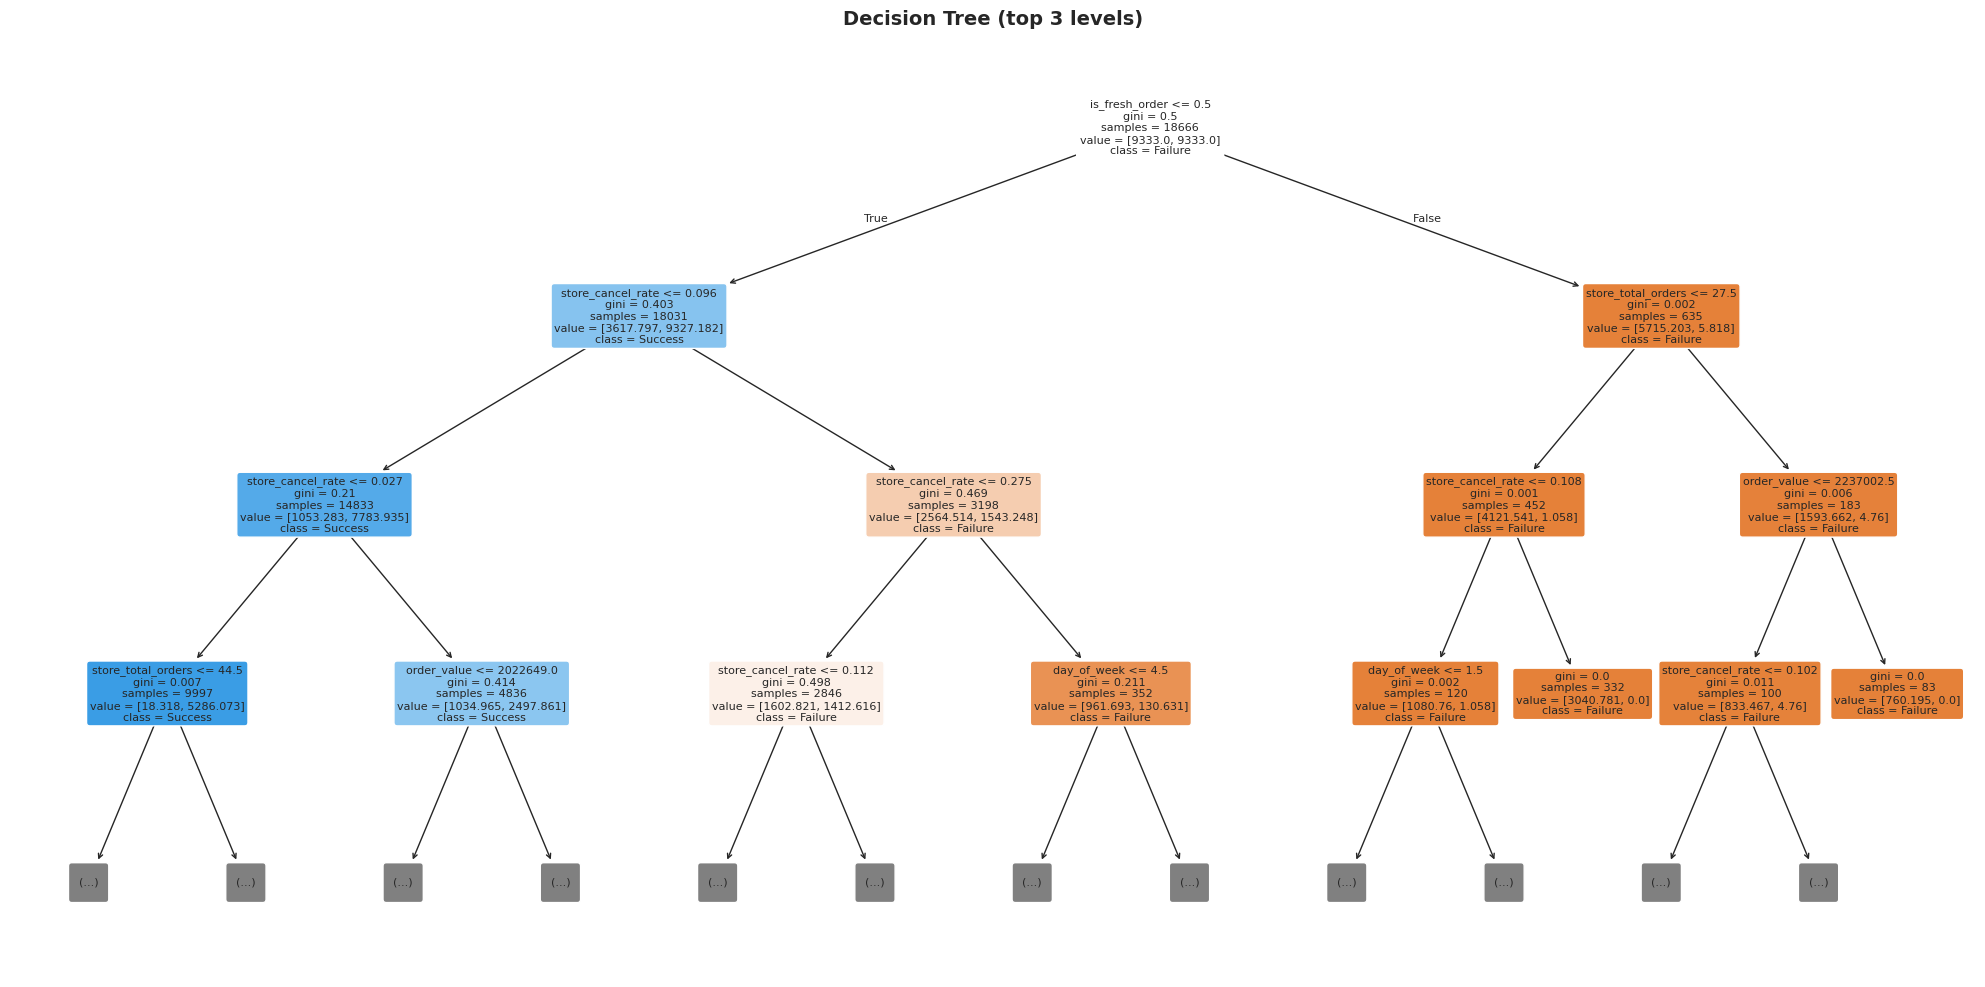

In [ ]:
# Model B: Decision Tree
model_dt = DecisionTreeClassifier(
    max_depth=5, min_samples_leaf=50, random_state=42, class_weight='balanced'
)
model_dt.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(model_dt, feature_names=final_features, class_names=['Failure', 'Success'],
          filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title("Decision Tree (top 3 levels)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig_decision_tree.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Decision Tree
The tree splits **first on `is_fresh_order`**, immediately isolating the 100%-cancellation category. Subsequent splits use `store_cancel_rate` and `order_value` to further separate risk groups.

> **So what?** The tree gives us **visual decision rules** that operations staff can follow without a model: *"If it's a Fresh Order → flag immediately. If the store's cancel rate > X% → escalate for review."* However, the tree achieves high Recall (catches many cancellations) at the cost of lower Precision (more false alarms).


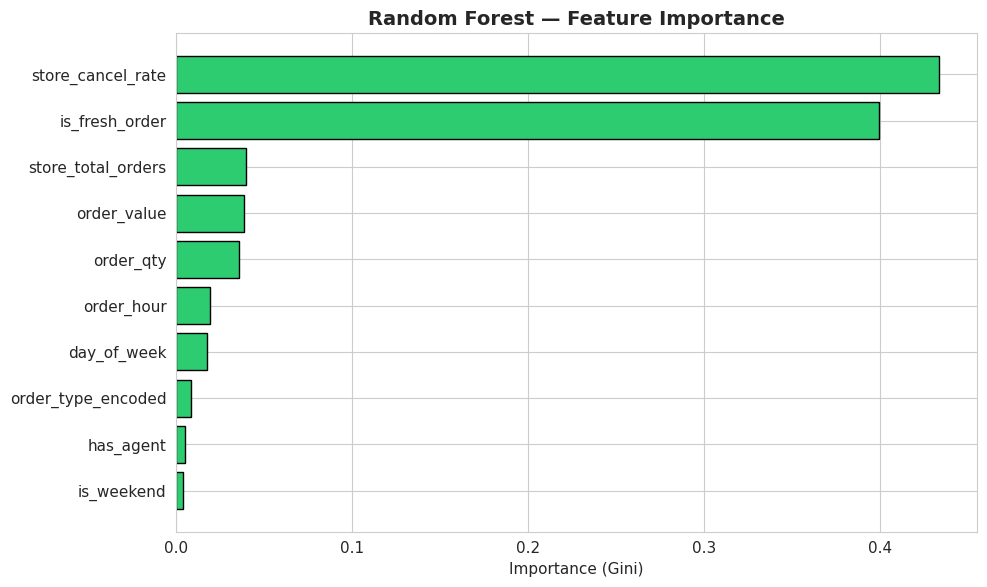

In [ ]:
# Model C: Random Forest
model_rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=20,
    random_state=42, class_weight='balanced', n_jobs=-1
)
model_rf.fit(X_train, y_train)

# Feature importance
imp_df = pd.DataFrame({
    'Feature': final_features, 'Importance': model_rf.feature_importances_
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp_df['Feature'], imp_df['Importance'], color='#2ecc71', edgecolor='black')
ax.set_title("Random Forest — Feature Importance", fontsize=14, fontweight='bold')
ax.set_xlabel("Importance (Gini)")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Feature Importance
The Random Forest confirms the same top predictors:
1. **`store_cancel_rate`** — a store's track record is the single best predictor
2. **`is_fresh_order`** — the Fresh Order category is a near-perfect signal
3. **`order_value`** — very large or unusual order values correlate with cancellations

> **So what?** The agreement across all three models (LogReg coefficients, Tree splits, RF importance) gives us **high confidence** that these are genuinely important features, not artefacts of a single algorithm.


## 9. Evaluation & Comparison
With 94.5% majority class, a naive model predicting "Success" always gets 94.5% accuracy but catches **zero** cancellations. We need metrics that evaluate the minority class.


In [ ]:
# Performance comparison
models = {
    'Logistic Regression': model_lr,
    'Decision Tree': model_dt,
    'Random Forest': model_rf
}

results = []
for name, model in models.items():
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    y_prob_test = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Train Acc': accuracy_score(y_train, y_pred_train),
        'Test Acc': accuracy_score(y_test, y_pred_test),
        'Precision': precision_score(y_test, y_pred_test, pos_label=0),
        'Recall': recall_score(y_test, y_pred_test, pos_label=0),
        'F1': f1_score(y_test, y_pred_test, pos_label=0),
        'AUC-ROC': roc_auc_score(y_test, y_prob_test),
    })

results_df = pd.DataFrame(results).round(4)
results_df


,Model,Train Acc,Test Acc,Precision,Recall,F1,AUC-ROC
0,Logistic Regression,0.9588,0.9569,0.5885,0.7002,0.6395,0.8921
1,Decision Tree,0.9138,0.9100,0.3546,0.7895,0.4894,0.9430
2,Random Forest,0.9519,0.9416,0.4782,0.7529,0.5849,0.9508


### Interpretation — Model Comparison

| Model | Recall | Precision | F1 | AUC-ROC | Trade-off |
|-------|--------|-----------|----|---------|-----------|
| **Logistic Regression** | 0.700 | 0.589 | **0.640** | 0.892 | Best balance of catching cancellations vs. false alarms |
| Decision Tree | **0.790** | 0.355 | 0.489 | 0.943 | Catches more cancellations but too many false positives |
| Random Forest | 0.753 | 0.478 | 0.585 | **0.951** | Best overall discrimination; useful with threshold tuning |
| *Naive Benchmark* | *0.000* | *N/A* | *0.000* | *0.500* | *Catches nothing — our baseline to beat* |

**Key takeaway:** All three models massively outperform the naive benchmark. Logistic Regression offers the best **practical** trade-off (F1 = 0.640) with full interpretability.

> **So what?** For deployment, we recommend **Logistic Regression** because (1) it catches 70% of cancellations, (2) its 58.9% precision means roughly 3 out of 5 flagged orders truly are at risk, and (3) the operations team can understand *why* each order was flagged.


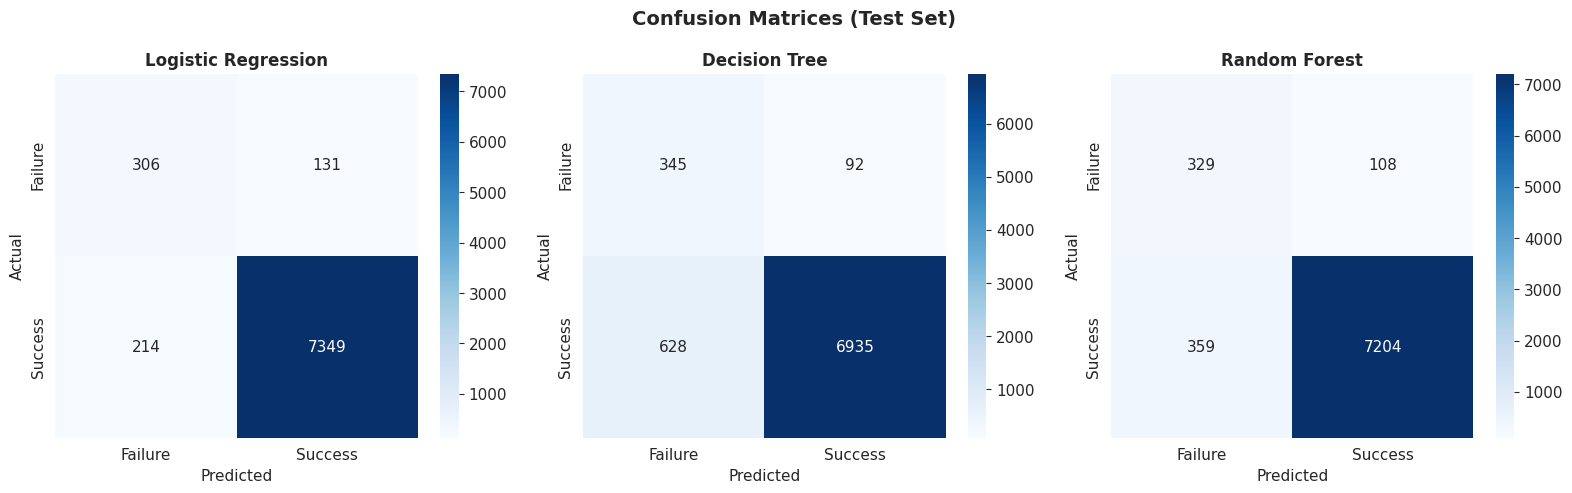

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, (name, model) in enumerate(models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Failure', 'Success'], yticklabels=['Failure', 'Success'])
    axes[i].set_title(name, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')
plt.suptitle("Confusion Matrices (Test Set)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("fig_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()


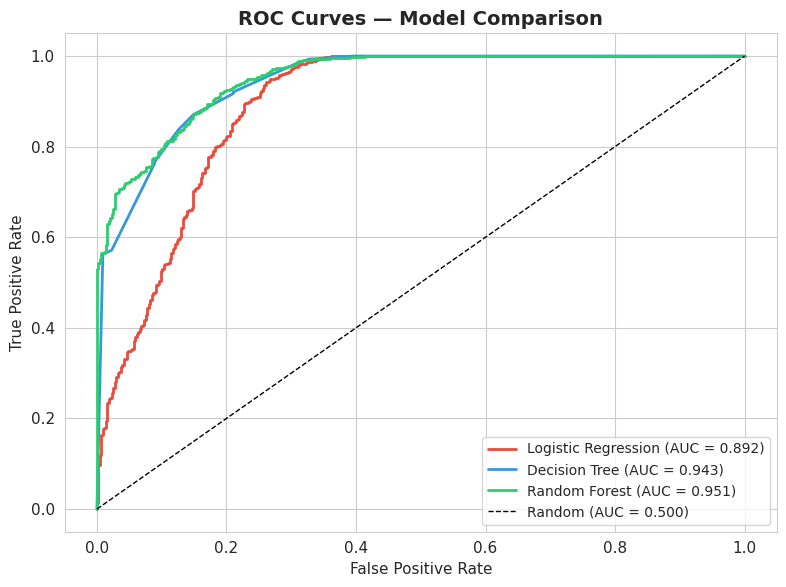

In [ ]:
# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#e74c3c', '#3498db', '#2ecc71']
for i, (name, model) in enumerate(models.items()):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, color=colors[i], linewidth=2, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.500)')
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Model Comparison", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("fig_roc_curves.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — ROC Curves
The ROC curve plots True Positive Rate (Recall) against False Positive Rate at every probability threshold. A perfect model hugs the top-left corner (AUC = 1.0); a random guess follows the diagonal (AUC = 0.5).

- **Random Forest (AUC = 0.951)** has the best overall discrimination — if we can tune the threshold in production, this model offers the most flexibility.
- **Decision Tree (AUC = 0.943)** is close but less smooth (fewer unique probability values due to leaf-based predictions).
- **Logistic Regression (AUC = 0.892)** is lower but still strong, and its default 0.5 threshold already produces a good practical trade-off.


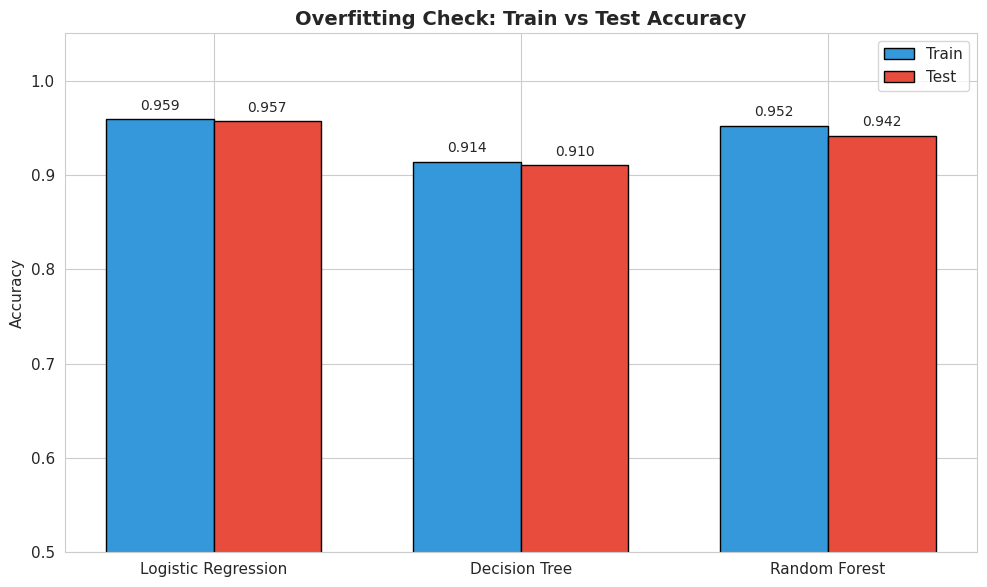

In [ ]:
# Overfitting check: Train vs Test accuracy
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(results_df))
width = 0.35
bars1 = ax.bar(x - width/2, results_df['Train Acc'], width, label='Train', color='#3498db', edgecolor='black')
bars2 = ax.bar(x + width/2, results_df['Test Acc'], width, label='Test', color='#e74c3c', edgecolor='black')
ax.set_ylabel('Accuracy'); ax.set_title('Overfitting Check: Train vs Test Accuracy', fontsize=14, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(results_df['Model'], fontsize=11)
ax.legend(); ax.set_ylim(0.5, 1.05)
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig("fig_overfitting_check.png", dpi=150, bbox_inches='tight')
plt.show()


### Interpretation — Overfitting Check
| Model | Train Acc | Test Acc | Gap |
|-------|-----------|----------|-----|
| Logistic Regression | 0.959 | 0.957 | **0.2 pp** — no overfitting |
| Decision Tree | 0.914 | 0.910 | 0.4 pp — no overfitting |
| Random Forest | 0.952 | 0.942 | 1.0 pp — minor, acceptable |

All gaps are small, confirming that our models **generalise well** to unseen data. The max_depth constraints on the tree-based models and the ensemble averaging of Random Forest effectively prevent memorisation.

> **So what?** This means we can trust the test-set metrics as realistic estimates of production performance.


## 10. Conclusions & Recommendations

### Key Findings
1. **Class imbalance** (94.5% vs 5.5%) makes accuracy misleading — F1 and AUC-ROC are the right metrics
2. **`is_fresh_order`** and **`store_cancel_rate`** dominate all models — the strongest business levers
3. **Logistic Regression** is the best deployment choice (F1 = 0.640, interpretable, minimal overfitting)
4. **Random Forest** offers the best AUC-ROC (0.951) if threshold tuning is feasible

### Limitations
- Data covers only July–December 2021 — seasonal patterns may differ in other periods
- `store_cancel_rate` is computed from full data (minor leakage risk — use only historical data in production)
- No product-level data — cancellations may be product-driven
- `is_fresh_order` has 100% cancellation rate — verify with business whether ORDER CATEGORY is known at order time

### Ethical Considerations
- **Fairness:** Flagging stores as "high-risk" could reduce their service, creating a self-fulfilling prophecy
- **Transparency:** Store owners should know why orders are flagged — Logistic Regression enables this
- **Privacy:** Store names and agent IDs are personally identifiable — anonymise before sharing

### Operational Recommendations
1. **Deploy as early-warning system** — score orders at placement, flag those with >50% failure probability for proactive verification calls
2. **Fix Fresh Order process** — 100% failure rate signals a systemic process issue, not a prediction problem. Audit immediately
3. **Enrich data** — collect product categories, payment method, delivery distance for better predictions
4. **Retrain quarterly** — monitor monthly, retrain on fresh data as patterns evolve
5. **A/B test interventions** — for flagged orders, test proactive calls vs. control to measure cancellation reduction
